In [3]:
from pathlib import Path

current_dir = Path.cwd()

if (current_dir / "data").exists():
    PROJECT_ROOT = current_dir
elif (current_dir.parent / "data").exists():
    PROJECT_ROOT = current_dir.parent
else:
    raise FileNotFoundError(
        "Project root not found. Please open Jupyter from the "
        "'wafer-map-defect-classification' folder."
    )

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"

print("Current working directory:", current_dir)
print("Project root:", PROJECT_ROOT)
print("Raw data directory:", RAW_DATA_DIR)
print("Files in raw data directory:", [file.name for file in RAW_DATA_DIR.iterdir()])

Current working directory: <LOCAL_PATH>
Project root: <LOCAL_PATH>
Raw data directory: <LOCAL_PATH>
Files in raw data directory: ['.DS_Store', 'WM811K_source.zip', '.gitkeep']


# 1. Data Audit

## 1.1 Inspect the Dataset Archive

In [4]:
import zipfile

DATA_ARCHIVE = RAW_DATA_DIR / "WM811K_source.zip"

with zipfile.ZipFile(DATA_ARCHIVE, "r") as archive:
    archive_files = archive.namelist()

print("Number of files in the archive:", len(archive_files))
print("Archive contents:", archive_files)

Number of files in the archive: 1
Archive contents: ['LSWMD.pkl']


## 1.2 Load the Wafer Map Dataset

In [5]:
import pickle
import zipfile


class LegacyPandasUnpickler(pickle.Unpickler):
    """Load WM-811K files created with an older pandas version."""

    def find_class(self, module, name):
        module = module.replace("pandas.indexes", "pandas.core.indexes")
        return super().find_class(module, name)


def load_wm811k(zip_path):
    """Load the single pickle file stored in the WM-811K archive."""

    with zipfile.ZipFile(zip_path, "r") as archive:
        pickle_name = [name for name in archive.namelist() if name.endswith(".pkl")][0]

        with archive.open(pickle_name) as file:
            return LegacyPandasUnpickler(file, encoding="latin1").load()


wm811k = load_wm811k(DATA_ARCHIVE)

print("Object type:", type(wm811k))
print("Dataset shape:", wm811k.shape)

Object type: <class 'pandas.DataFrame'>
Dataset shape: (811457, 6)


## 1.3 Inspect the Dataset Structure

In [6]:
print("Column names:")
print(wm811k.columns.tolist())

print("\nData types:")
print(wm811k.dtypes)

print("\nFirst three records without the wafer map matrix:")
display(wm811k.drop(columns="waferMap").head(3))

first_wafer_map = wm811k.loc[0, "waferMap"]

print("\nFirst wafer map shape:", first_wafer_map.shape)
print("Values used in the first wafer map:", sorted(set(first_wafer_map.ravel())))

Column names:
['waferMap', 'dieSize', 'lotName', 'waferIndex', 'trianTestLabel', 'failureType']

Data types:
waferMap           object
dieSize           float64
lotName            object
waferIndex        float64
trianTestLabel     object
failureType        object
dtype: object

First three records without the wafer map matrix:


,dieSize,lotName,waferIndex,trianTestLabel,failureType
0,1683.0,lot1,1.0,[[Training]],[[none]]
1,1683.0,lot1,2.0,[[Training]],[[none]]
2,1683.0,lot1,3.0,[[Training]],[[none]]



First wafer map shape: (45, 48)
Values used in the first wafer map: [np.uint8(0), np.uint8(1), np.uint8(2)]


## 1.4 Inspect Labels and Dataset Availability

In [8]:
import numpy as np
import pandas as pd


def extract_label(value):
    """Convert an array- or list-wrapped label into a plain string."""

    if isinstance(value, (np.ndarray, list, tuple)):
        return value[0] if len(value) > 0 else None

    return value


metadata = wm811k[
    ["dieSize", "lotName", "waferIndex", "trianTestLabel", "failureType"]
].copy()

metadata["split"] = metadata["trianTestLabel"].apply(extract_label)
metadata["failure_type"] = metadata["failureType"].apply(extract_label)

print("Raw split counts:")
print(metadata["split"].fillna("Unassigned").value_counts())

print("\nFailure-type counts, including unlabeled records:")
print(metadata["failure_type"].fillna("Unlabeled").value_counts())

labeled_metadata = metadata[metadata["failure_type"].notna()].copy()

print("\nNumber of labeled wafer maps:", len(labeled_metadata))
print("Number of unlabeled wafer maps:", len(metadata) - len(labeled_metadata))

Raw split counts:
split
Unassigned    638507
[Test]        118595
[Training]     54355
Name: count, dtype: int64

Failure-type counts, including unlabeled records:
failure_type
Unlabeled      638507
[none]         147431
[Edge-Ring]      9680
[Edge-Loc]       5189
[Center]         4294
[Loc]            3593
[Scratch]        1193
[Random]          866
[Donut]           555
[Near-full]       149
Name: count, dtype: int64

Number of labeled wafer maps: 172950
Number of unlabeled wafer maps: 638507


In [9]:
def extract_label(value):
    """Convert nested list- or array-wrapped labels into plain strings."""

    while isinstance(value, (np.ndarray, list, tuple)):
        if len(value) == 0:
            return None
        value = value[0]

    return value


metadata = wm811k[
    ["dieSize", "lotName", "waferIndex", "trianTestLabel", "failureType"]
].copy()

metadata["split"] = metadata["trianTestLabel"].apply(extract_label)
metadata["failure_type"] = metadata["failureType"].apply(extract_label)

print("Raw split counts:")
print(metadata["split"].fillna("Unassigned").value_counts())

print("\nFailure-type counts, including unlabeled records:")
print(metadata["failure_type"].fillna("Unlabeled").value_counts())

labeled_metadata = metadata[metadata["failure_type"].notna()].copy()

print("\nNumber of labeled wafer maps:", len(labeled_metadata))
print("Number of unlabeled wafer maps:", len(metadata) - len(labeled_metadata))

Raw split counts:
split
Unassigned    638507
Test          118595
Training       54355
Name: count, dtype: int64

Failure-type counts, including unlabeled records:
failure_type
Unlabeled    638507
none         147431
Edge-Ring      9680
Edge-Loc       5189
Center         4294
Loc            3593
Scratch        1193
Random          866
Donut           555
Near-full       149
Name: count, dtype: int64

Number of labeled wafer maps: 172950
Number of unlabeled wafer maps: 638507


## 1.5 Visualize Class Imbalance

,count,percentage
failure_type,,
none,147431,85.24
Edge-Ring,9680,5.60
Edge-Loc,5189,3.00
Center,4294,2.48
Loc,3593,2.08
Scratch,1193,0.69
Random,866,0.50
Donut,555,0.32
Near-full,149,0.09


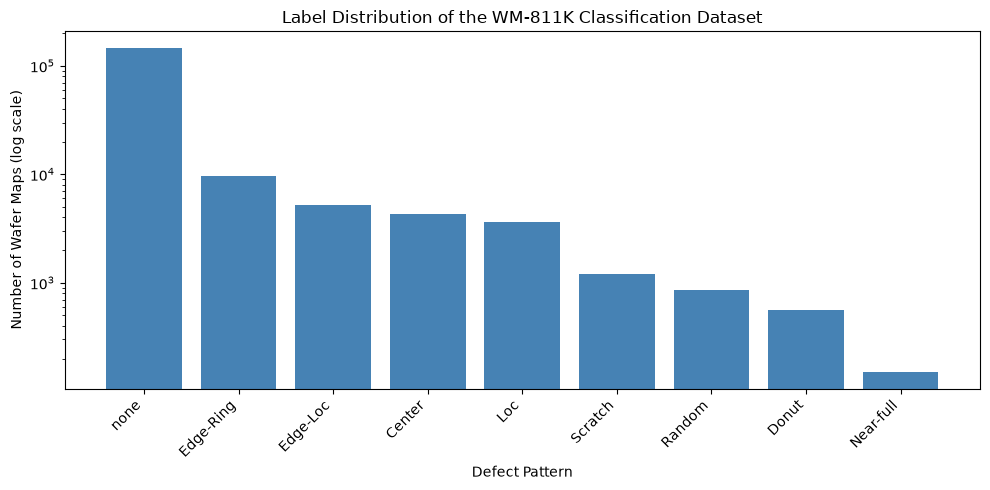

Figure saved to: <LOCAL_PATH>


In [10]:
import matplotlib.pyplot as plt

class_counts = labeled_metadata["failure_type"].value_counts()
class_percentages = class_counts / class_counts.sum() * 100

class_summary = pd.DataFrame(
    {
        "count": class_counts,
        "percentage": class_percentages.round(2),
    }
)

display(class_summary)

FIGURES_DIR = PROJECT_ROOT / "figures"
FIGURES_DIR.mkdir(exist_ok=True)

plt.figure(figsize=(10, 5))

plt.bar(class_counts.index, class_counts.values, color="steelblue")

plt.yscale("log")
plt.xlabel("Defect Pattern")
plt.ylabel("Number of Wafer Maps (log scale)")
plt.title("Label Distribution of the WM-811K Classification Dataset")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()

figure_path = FIGURES_DIR / "01_class_distribution_log_scale.png"
plt.savefig(figure_path, dpi=200, bbox_inches="tight")

plt.show()

print(f"Figure saved to: {figure_path}")

## 1.6 Visualize One Wafer Map per Defect Pattern

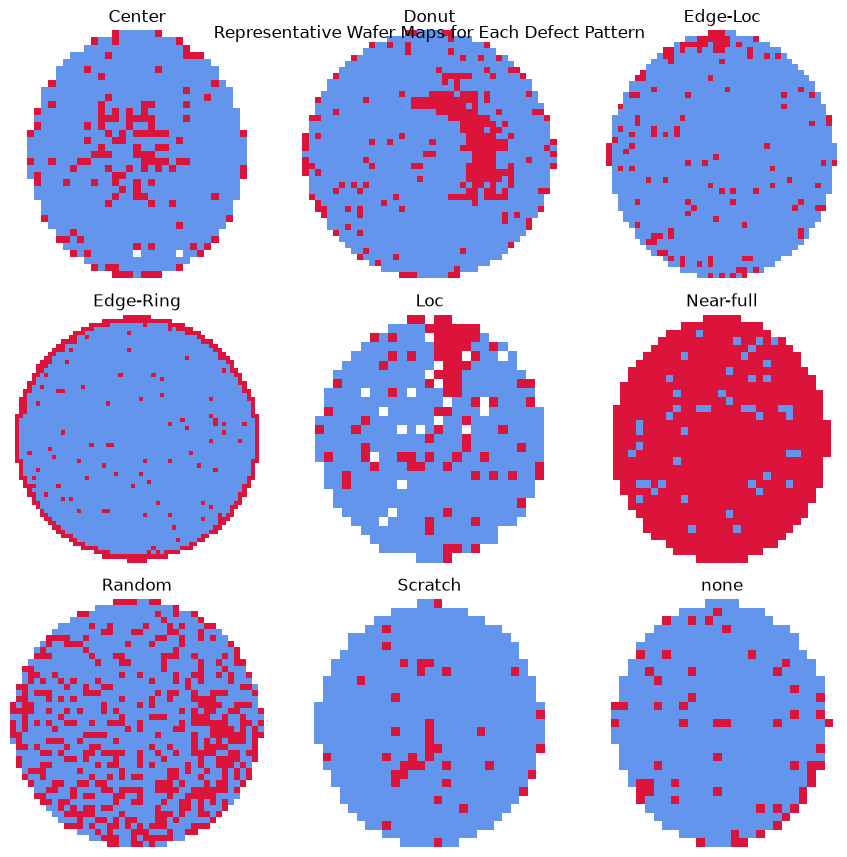

Figure saved to: <LOCAL_PATH>


In [11]:
from matplotlib.colors import ListedColormap

CLASS_NAMES = [
    "Center",
    "Donut",
    "Edge-Loc",
    "Edge-Ring",
    "Loc",
    "Near-full",
    "Random",
    "Scratch",
    "none",
]

wafer_cmap = ListedColormap(["white", "cornflowerblue", "crimson"])

fig, axes = plt.subplots(3, 3, figsize=(9, 9))

for axis, class_name in zip(axes.ravel(), CLASS_NAMES):
    example_index = labeled_metadata[
        labeled_metadata["failure_type"] == class_name
    ].sample(n=1, random_state=42).index[0]

    wafer_map = wm811k.at[example_index, "waferMap"]

    axis.imshow(wafer_map, cmap=wafer_cmap, vmin=0, vmax=2)
    axis.set_title(class_name)
    axis.axis("off")

fig.suptitle("Representative Wafer Maps for Each Defect Pattern", y=0.93)
plt.tight_layout()

figure_path = FIGURES_DIR / "02_wafer_map_examples.png"
plt.savefig(figure_path, dpi=200, bbox_inches="tight")

plt.show()

print(f"Figure saved to: {figure_path}")

## 1.7 Inspect Wafer Map Dimensions

In [12]:
labeled_map_shapes = wm811k.loc[
    labeled_metadata.index, "waferMap"
].apply(lambda wafer_map: wafer_map.shape)

map_heights = labeled_map_shapes.apply(lambda shape: shape[0])
map_widths = labeled_map_shapes.apply(lambda shape: shape[1])

print("Number of unique map shapes:", labeled_map_shapes.nunique())

print("\nHeight range:")
print("Minimum height:", map_heights.min())
print("Maximum height:", map_heights.max())

print("\nWidth range:")
print("Minimum width:", map_widths.min())
print("Maximum width:", map_widths.max())

print("\nTen most common map shapes:")
print(labeled_map_shapes.value_counts().head(10))

Number of unique map shapes: 346

Height range:
Minimum height: 15
Maximum height: 212

Width range:
Minimum width: 3
Maximum width: 204

Ten most common map shapes:
waferMap
(25, 27)    18781
(26, 26)    14366
(30, 34)    12400
(29, 26)    11751
(27, 25)    10682
(39, 37)    10173
(33, 29)     8125
(42, 44)     6724
(44, 41)     6134
(41, 33)     5091
Name: count, dtype: int64


## 1.8 Check Lot Separation Between Training and Test Sets

In [13]:
training_data = labeled_metadata[
    labeled_metadata["split"] == "Training"
].copy()

test_data = labeled_metadata[
    labeled_metadata["split"] == "Test"
].copy()

training_lots = set(training_data["lotName"])
test_lots = set(test_data["lotName"])

overlapping_lots = training_lots.intersection(test_lots)

print("Number of labeled training wafers:", len(training_data))
print("Number of labeled test wafers:", len(test_data))

print("\nNumber of training lots:", len(training_lots))
print("Number of test lots:", len(test_lots))
print("Number of overlapping lots:", len(overlapping_lots))

print("\nClass distribution by original split:")
display(
    pd.crosstab(
        labeled_metadata["failure_type"],
        labeled_metadata["split"],
    )
)

Number of labeled training wafers: 54355
Number of labeled test wafers: 118595

Number of training lots: 5809
Number of test lots: 4953
Number of overlapping lots: 0

Class distribution by original split:


split,Test,Training
failure_type,,
Center,832,3462
Donut,146,409
Edge-Loc,2772,2417
Edge-Ring,1126,8554
Loc,1973,1620
Near-full,95,54
Random,257,609
Scratch,693,500
none,110701,36730


## 1.9 Data Audit Summary

- The WM-811K dataset contains 811,457 wafer-map records and six original fields.
- Each wafer map is represented as a two-dimensional matrix with values 0, 1, and 2, corresponding to background, normal dies, and defective dies.
- Only 172,950 wafer maps have defect-pattern labels and can be used for supervised classification.
- The labeled subset contains nine classes and is highly imbalanced. The `none` class accounts for 85.24% of labeled samples, while `Near-full` contains only 149 samples.
- The labeled wafer maps have 346 different spatial dimensions, so a consistent input size is required before CNN training.
- The original Training and Test sets contain no overlapping lots, reducing the risk of lot-level data leakage.
- The class distributions differ substantially between the original Training and Test sets, so accuracy alone is not an appropriate evaluation metric.
- The next stage will create lot-aware training and validation subsets, standardize the wafer-map dimensions, and prepare PyTorch-compatible inputs.